In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/sarifasiddikaa/final-results-15k/metablock_seed4.pth
/kaggle/input/datasets/sarifasiddikaa/final-results-15k/fusion_seed4.pth
/kaggle/input/datasets/sarifasiddikaa/final-results-15k/metablock_seed5.pth
/kaggle/input/datasets/sarifasiddikaa/final-results-15k/fusion_seed1.pth
/kaggle/input/datasets/sarifasiddikaa/final-results-15k/metablock_seed3.pth
/kaggle/input/datasets/sarifasiddikaa/final-results-15k/fusion_seed5.pth
/kaggle/input/datasets/sarifasiddikaa/final-results-15k/fusion_seed2.pth
/kaggle/input/datasets/sarifasiddikaa/final-results-15k/fusion_seed3.pth
/kaggle/input/datasets/sarifasiddikaa/final-results-15k/final_predictions_per_sample.csv
/kaggle/input/datasets/sarifasiddikaa/final-results-15k/metablock_seed2.pth
/kaggle/input/datasets/sarifasiddikaa/final-results-15k/metablock_seed1.pth


CSV_PATH not found, searched and found: ['/kaggle/input/datasets/sarifasiddikaa/final-results-15k/final_predictions_per_sample.csv']
Using: /kaggle/input/datasets/sarifasiddikaa/final-results-15k/final_predictions_per_sample.csv
Columns found in CSV: ['seed', 'isic_id', 'true_label', 'fusion_prob_0', 'fusion_prob_1', 'mb_prob_0', 'mb_prob_1']
   seed       isic_id  true_label  fusion_prob_0  fusion_prob_1  mb_prob_0  \
0     1  ISIC_0025105           1       0.132122       0.867878   0.116286   
1     1  ISIC_0067614           1       0.174059       0.825941   0.125306   
2     1  ISIC_0033171           1       0.202601       0.797399   0.232659   
3     1  ISIC_7035246           1       0.227169       0.772831   0.224395   
4     1  ISIC_0033754           1       0.398224       0.601776   0.239349   

   mb_prob_1  
0   0.883713  
1   0.874694  
2   0.767341  
3   0.775605  
4   0.760651  


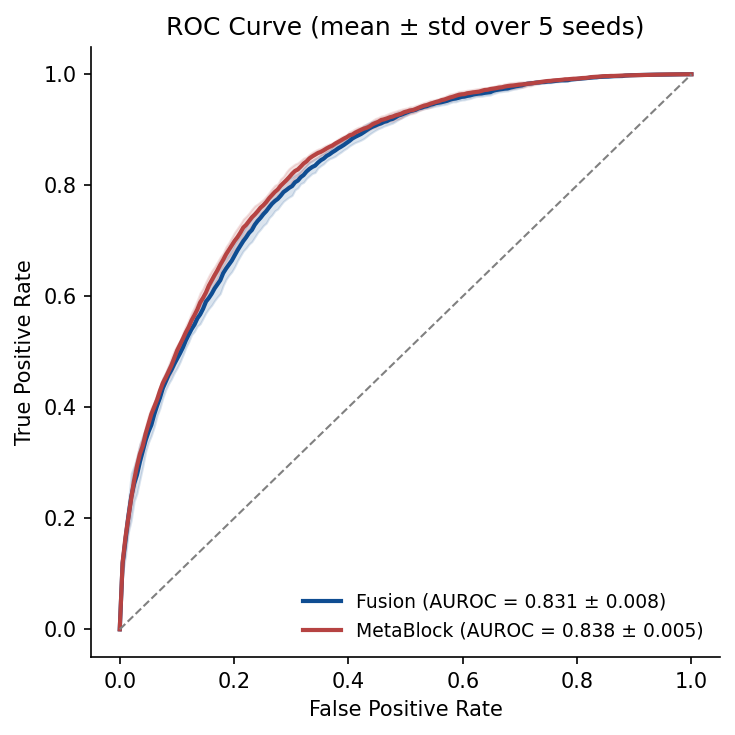

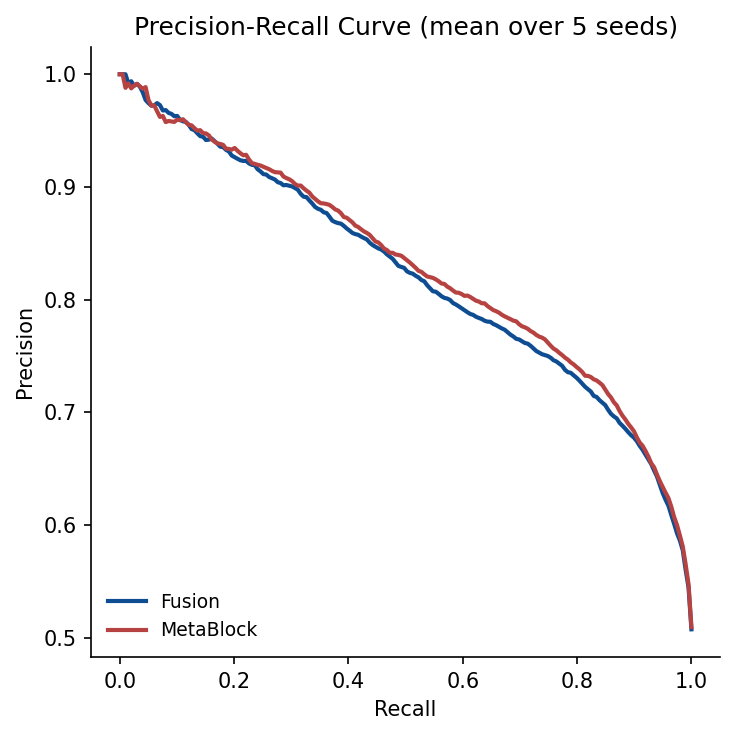

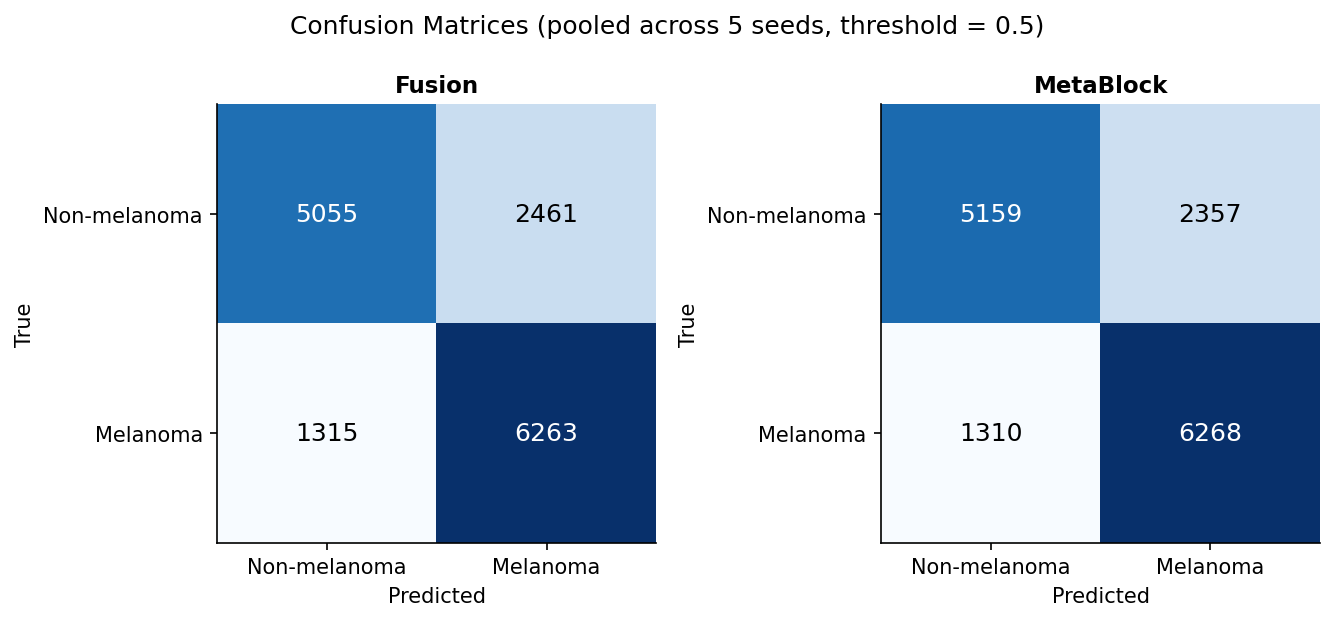

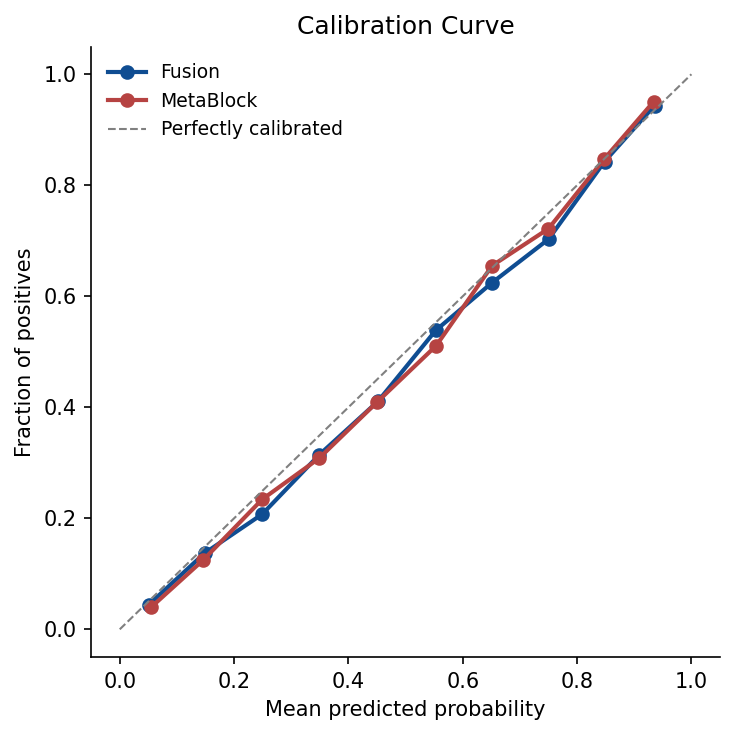


All 4 figures saved: roc_curve, pr_curve, confusion_matrices, calibration_curve (PNG @300dpi + PDF)


In [2]:
"""
Result figures for the paper: ROC curves, Precision-Recall curves,
Confusion matrices, and Calibration (reliability) curves for
Fusion vs MetaBlock on ISIC-DICM-17K, pooled across 5 seeds.

INPUT: final_predictions_per_sample.csv
Expected columns (EDIT the CONFIG block below if your names differ):
  - seed column        : which seed this row came from (1..5)
  - true label column  : ground truth (0 = non-melanoma, 1 = melanoma)
  - fusion prob column : Fusion model's predicted P(melanoma)
  - metablock prob col : MetaBlock model's predicted P(melanoma)
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, confusion_matrix
from sklearn.calibration import calibration_curve
import glob

# ============== CONFIG — edit these 4 lines if your CSV column names differ ==============
CSV_PATH        = "/kaggle/input/final-results-15k/final_predictions_per_sample.csv"
COL_SEED        = "seed"
COL_TRUE        = "true_label"
COL_FUSION_PROB = "fusion_prob_1"
COL_MB_PROB     = "mb_prob_1"
# ===========================================================================================

# find the real path if the guess above is wrong (Kaggle sometimes mounts datasets deeper)
import os
if not os.path.exists(CSV_PATH):
    matches = glob.glob("/kaggle/input/**/final_predictions_per_sample.csv", recursive=True)
    print("CSV_PATH not found, searched and found:", matches)
    assert matches, "Could not find final_predictions_per_sample.csv anywhere under /kaggle/input. Check the dataset is added as Input to this notebook."
    CSV_PATH = matches[0]
    print("Using:", CSV_PATH)

df = pd.read_csv(CSV_PATH)
print("Columns found in CSV:", df.columns.tolist())
print(df.head())

# sanity check before plotting — stop early with a clear message if names are wrong
for col in [COL_SEED, COL_TRUE, COL_FUSION_PROB, COL_MB_PROB]:
    assert col in df.columns, f"Column '{col}' not found. Fix the CONFIG block using the column list printed above."

# ---------------- house style ----------------
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "legend.frameon": False,
    "figure.dpi": 150,
})
COLOR_FUSION    = "#0F4D92"   # blue_main
COLOR_METABLOCK = "#B64342"   # red

models = {
    "Fusion":    (COL_FUSION_PROB, COLOR_FUSION),
    "MetaBlock": (COL_MB_PROB,     COLOR_METABLOCK),
}

y_true_all = df[COL_TRUE].values

# ============================================================
# 1. ROC curves (mean +/- std across 5 seeds)
# ============================================================
fig, ax = plt.subplots(figsize=(5, 5))
mean_fpr = np.linspace(0, 1, 200)

for name, (prob_col, color) in models.items():
    tprs, aucs = [], []
    for s in sorted(df[COL_SEED].unique()):
        sub = df[df[COL_SEED] == s]
        fpr, tpr, _ = roc_curve(sub[COL_TRUE], sub[prob_col])
        tprs.append(np.interp(mean_fpr, fpr, tpr))
        tprs[-1][0] = 0.0
        aucs.append(auc(fpr, tpr))
    mean_tpr = np.mean(tprs, axis=0)
    mean_tpr[-1] = 1.0
    std_tpr = np.std(tprs, axis=0)
    mean_auc, std_auc = np.mean(aucs), np.std(aucs)

    ax.plot(mean_fpr, mean_tpr, color=color, lw=2,
            label=f"{name} (AUROC = {mean_auc:.3f} ± {std_auc:.3f})")
    ax.fill_between(mean_fpr, np.maximum(mean_tpr - std_tpr, 0),
                     np.minimum(mean_tpr + std_tpr, 1), color=color, alpha=0.15)

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", lw=1)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve (mean ± std over 5 seeds)")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=300)
plt.savefig("roc_curve.pdf")
plt.show()

# ============================================================
# 2. Precision-Recall curves (mean over 5 seeds)
# ============================================================
fig, ax = plt.subplots(figsize=(5, 5))
mean_recall = np.linspace(0, 1, 200)

for name, (prob_col, color) in models.items():
    precisions = []
    for s in sorted(df[COL_SEED].unique()):
        sub = df[df[COL_SEED] == s]
        prec, rec, _ = precision_recall_curve(sub[COL_TRUE], sub[prob_col])
        # precision_recall_curve returns recall descending; sort ascending for interp
        order = np.argsort(rec)
        precisions.append(np.interp(mean_recall, rec[order], prec[order]))
    mean_prec = np.mean(precisions, axis=0)
    ax.plot(mean_recall, mean_prec, color=color, lw=2, label=name)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curve (mean over 5 seeds)")
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.savefig("pr_curve.png", dpi=300)
plt.savefig("pr_curve.pdf")
plt.show()

# ============================================================
# 3. Confusion matrices (pooled across all seeds, threshold = 0.5)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))

for ax, (name, (prob_col, color)) in zip(axes, models.items()):
    y_pred = (df[prob_col].values >= 0.5).astype(int)
    cm = confusion_matrix(y_true_all, y_pred)
    im = ax.imshow(cm, cmap="Blues")
    ax.set_title(name, fontsize=11, fontweight="bold")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Non-melanoma", "Melanoma"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Non-melanoma", "Melanoma"])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)

plt.suptitle("Confusion Matrices (pooled across 5 seeds, threshold = 0.5)")
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=300)
plt.savefig("confusion_matrices.pdf")
plt.show()

# ============================================================
# 4. Calibration (reliability) curves
# ============================================================
fig, ax = plt.subplots(figsize=(5, 5))

for name, (prob_col, color) in models.items():
    frac_pos, mean_pred = calibration_curve(y_true_all, df[prob_col].values, n_bins=10)
    ax.plot(mean_pred, frac_pos, marker="o", color=color, lw=2, label=name)

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", lw=1, label="Perfectly calibrated")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Fraction of positives")
ax.set_title("Calibration Curve")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.savefig("calibration_curve.png", dpi=300)
plt.savefig("calibration_curve.pdf")
plt.show()

print("\nAll 4 figures saved: roc_curve, pr_curve, confusion_matrices, calibration_curve (PNG @300dpi + PDF)")